# Week 2 — EDA + Preprocessing Notebook

**Course:** Introduction to Machine Learning     
**Project:** Machine Learners
**Team:** Myktybek Aksungkar, Yerkinbek Oren, Gazhbek Aruzhan, Aushet Askhat    
**Dataset:** Bank Marketing (UCI #222)  
**Task type:** Classification    
**Target variable:** `y` (whether the client subscribed to a term deposit)

---

## 1️⃣ Project context

From our Week 1 proposal, the goal is to predict whether a client subscribes to a term deposit.  
The dataset contains direct marketing campaign information from a Portuguese bank, with 45,211 observations and a mix of numerical and categorical features describing client demographics and campaign interactions.  
This is a binary classification problem, and the target variable is highly imbalanced: about 88% of clients did not subscribe, while only 12% subscribed, so class imbalance may affect model performance and must be handled carefully during modelling.

We expect **duration**, **previous**, **education**, and **job** to carry strong predictive value.  
For example, **duration** is known to have a strong relationship with the target variable, while **previous** reflects past client interactions. It is also important to note that **duration** may introduce data leakage, since it is only known after the call is completed.

The main objective of the preprocessing stage is to make the data cleaner, more informative, and suitable for machine learning algorithms by handling missing values, encoding categorical variables, and addressing skewness and outliers.

### What this notebook does
- loads and inspects the dataset
- performs EDA with at least 6 plots
- handles missing or special values with a clear strategy
- applies encoding and a small feature transformation
- scales numerical features using a leakage-safe order
- finishes with a train/test split ready for modelling

---

## 2️⃣ Imports and notebook settings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')

## 3️⃣ Load the dataset

In [2]:
bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features
y = bank_marketing.data.targets

df = pd.concat([X, y], axis=1)

print('Dataset loaded successfully!')
print('Shape:', df.shape)
print(f'\n{df.head()}')

Dataset loaded successfully!
Shape: (45211, 17)

   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married        NaN      no     1506     yes   no   
4   33           NaN   single        NaN      no        1      no   no   

  contact  day_of_week month  duration  campaign  pdays  previous poutcome   y  
0     NaN            5   may       261         1     -1         0      NaN  no  
1     NaN            5   may       151         1     -1         0      NaN  no  
2     NaN            5   may        76         1     -1         0      NaN  no  
3     NaN            5   may        92         1     -1         0      NaN  no  
4     NaN            5   may       198         1     -1         0      NaN  no  


## 4️⃣ Dataset overview

We first inspect the table structure, data types, missing values, and summary statistics.  
For a classification task, we also show the target distribution so we can judge class imbalance early.

In [3]:
print("Data types:")
print(df.dtypes)


Data types:
age            int64
job              str
marital          str
education        str
default          str
balance        int64
housing          str
loan             str
contact          str
day_of_week    int64
month            str
duration       int64
campaign       int64
pdays          int64
previous       int64
poutcome         str
y                str
dtype: object


In [4]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64


In [5]:
print("Descriptive statistics:")
display(df.describe())

Descriptive statistics:


,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [6]:
print("Target distribution:")
print(df['y'].value_counts())

print("\nTarget distribution (%):")
print(df['y'].value_counts(normalize=True).round(2))

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target distribution (%):
y
no     0.88
yes    0.12
Name: proportion, dtype: float64


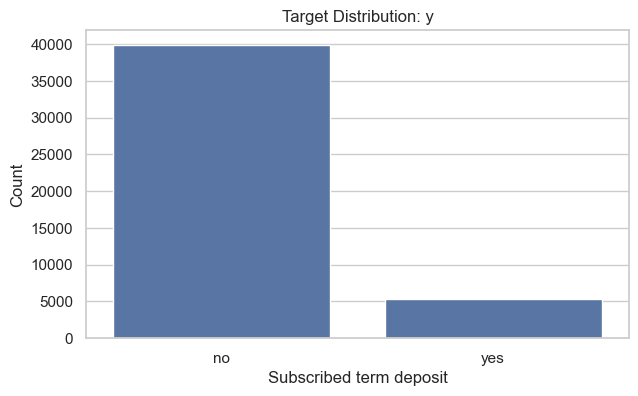

In [7]:
plt.figure(figsize=(7, 4))
sns.countplot(x='y', data=df)
plt.title("Target Distribution: y")
plt.xlabel("Subscribed term deposit")
plt.ylabel("Count")
plt.show()

### Dataset summary   
The dataset contains direct marketing campaign information from a Portuguese bank.  
Each row represents one client contact, and the target column `y` tells us whether the client subscribed to a term deposit.  
This is a binary classification problem, so class balance matters and we check the target distribution before modelling.  
Based on our proposal, we focus especially on `duration`, `previous`, `education`, and `job` because they are expected to carry strong predictive value.  
The main objective of the preprocessing stage is to make the data cleaner, more informative, and safe for machine learning algorithms.

---

## 5️⃣ Exploratory Data Analysis

The rubric requires at least 6 distinct plots, including:
- a histogram for a numerical feature
- a boxplot by category
- a correlation heatmap
- a countplot for the target variable

Each plot below is followed by a short interpretation.

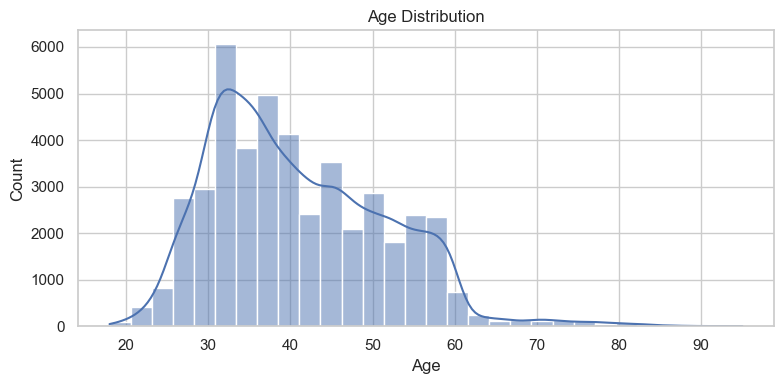

In [8]:
plt.figure(figsize=(8, 4))
sns.histplot(df["age"], bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

**Interpretation:**  
Age usually shows whether the campaign is reaching a broad customer base or concentrating on a specific group.  
If the distribution is right-skewed or concentrated in middle ages, it suggests that the bank mostly contacted working-age clients, which may affect subscription patterns.   

---

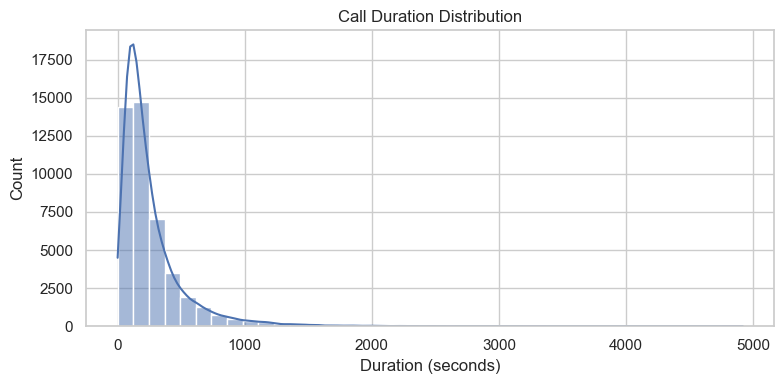

In [9]:
plt.figure(figsize=(8, 4))
sns.histplot(df["duration"], bins=40, kde=True)
plt.title("Call Duration Distribution")
plt.xlabel("Duration (seconds)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

**Interpretation:**  
Call duration is expected to be highly informative because it reflects how long the client stayed engaged during the call.  
A strongly skewed distribution is normal here and supports the idea that a transformation such as `log1p` can make the feature easier to work with.   

---

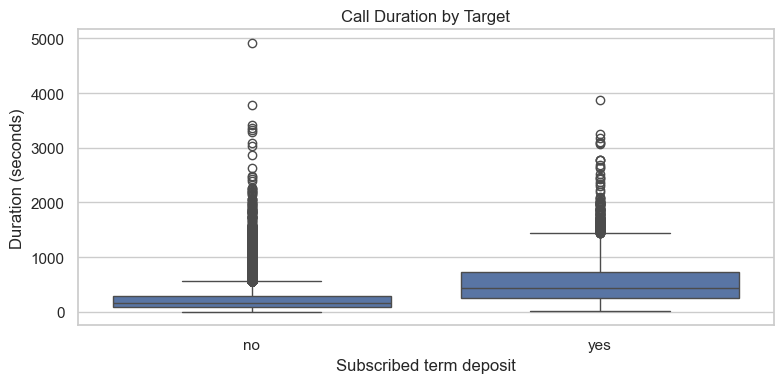

In [10]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["y"], y=df["duration"], data=df)
plt.title("Call Duration by Target")
plt.xlabel("Subscribed term deposit")
plt.ylabel("Duration (seconds)")
plt.tight_layout()
plt.show()

**Interpretation:**  
This boxplot helps us compare call duration between the `yes` and `no` classes.  
If the `yes` group has a noticeably higher median or wider upper range, it supports the hypothesis that longer conversations are linked to higher subscription probability.

---

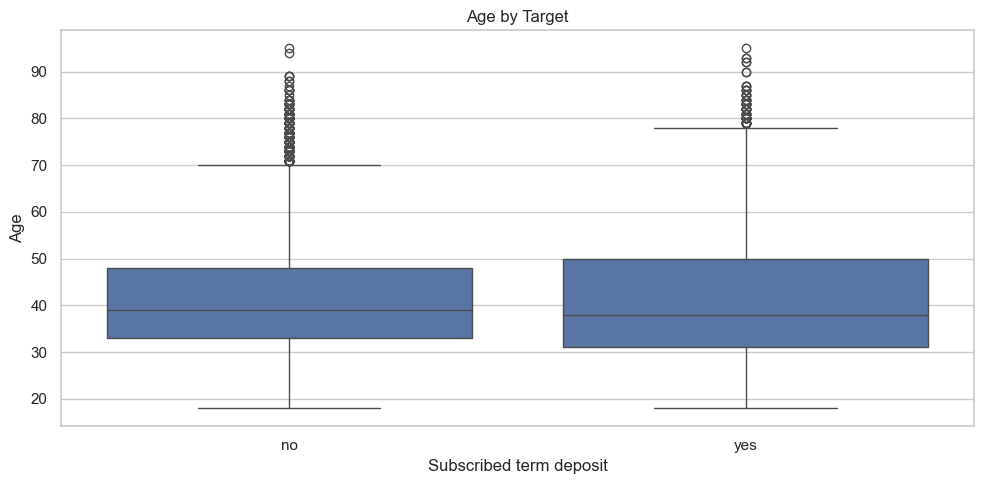

In [11]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["y"], y=df["age"], data=df)
plt.title("Age by Target")
plt.xlabel("Subscribed term deposit")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

**Interpretation:**  
This plot shows whether age differs between subscribers and non-subscribers.  
Even if the separation is weak, it can still contribute to the model when combined with other demographic and campaign variables.

---

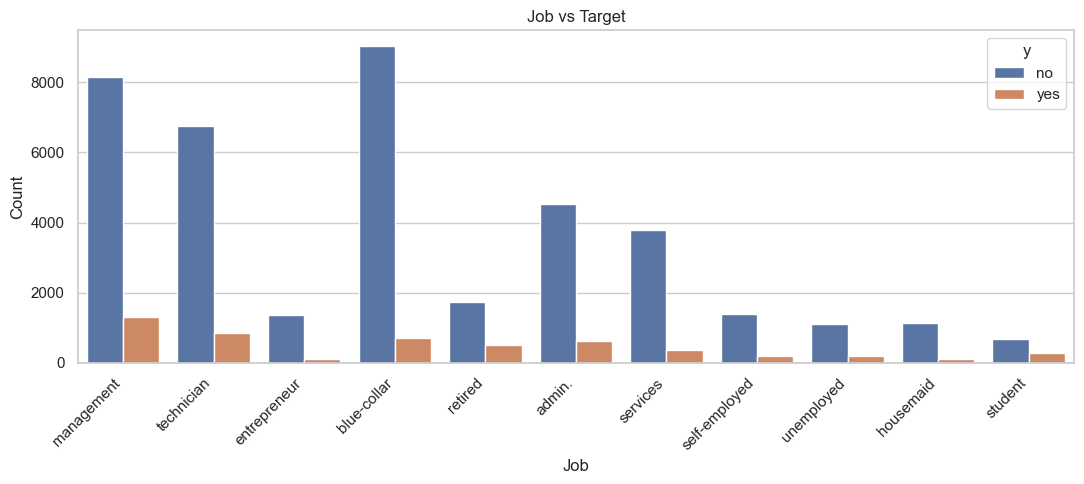

In [12]:
plt.figure(figsize=(11, 5))
sns.countplot(x="job", hue="y", data=df)
plt.title("Job vs Target")
plt.xlabel("Job")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.legend(title="y")
plt.tight_layout()
plt.show()

**Interpretation:**  
Occupation can reflect income level, stability, and financial behaviour, so it is a reasonable categorical predictor.  
If some jobs show a visibly larger `yes` share, one-hot encoding is justified because the categories are nominal and should not be forced into an artificial order.  

---

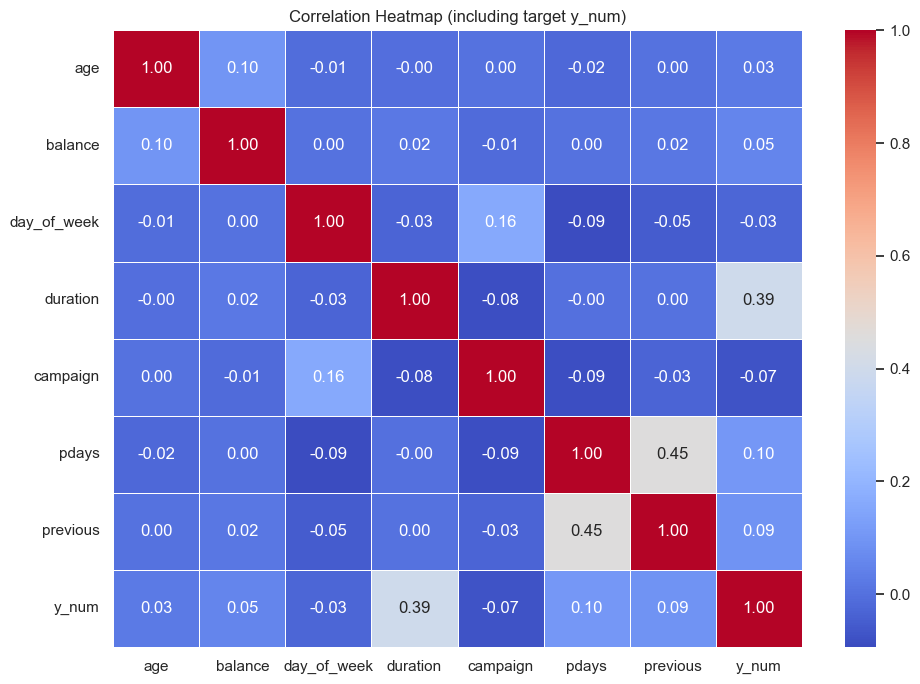

In [13]:
# Add numeric target for correlation
df_corr = df.select_dtypes(include=['int64', 'float64']).copy()
df_corr['y_num'] = (df['y'] == 'yes').astype(int)

plt.figure(figsize=(10, 7))
corr = df_corr.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap (including target y_num)')
plt.tight_layout()
plt.show()

**Interpretation:**  
The heatmap reveals pairwise correlations among all numeric features plus the binary target (`y_num = 1` if subscribed).  
`duration` shows the strongest positive correlation with `y_num` (~0.39), confirming our Week 1 hypothesis.  
`campaign` shows a slight negative correlation, suggesting that more call attempts are weakly associated with lower subscription probability.  
`pdays` and `previous` are moderately correlated with each other, which is expected as both capture prior contact history.

---

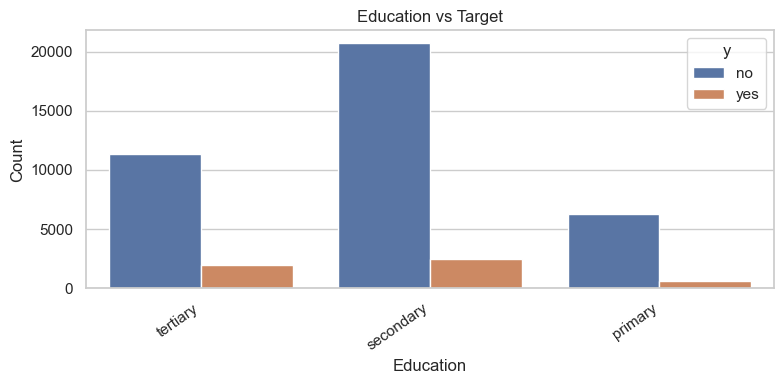

In [14]:
plt.figure(figsize=(8, 4))
sns.countplot(x="education", hue="y", data=df)
plt.title("Education vs Target")
plt.xlabel("Education")
plt.ylabel("Count")
plt.xticks(rotation=35, ha="right")
plt.legend(title="y")
plt.tight_layout()
plt.show()

**Interpretation:**  
Education is ordinal in real life, so it is a good candidate for ordered encoding instead of one-hot encoding.  
If higher education levels show a stronger subscription rate, that supports our Week 1 hypothesis and gives the model a meaningful ranking signal.  

---

## 6️⃣ Missing values and special-category handling

We handle missing values column-by-column with an explicit strategy for each.

| Column | Missing | Strategy | Reason |
|---|---|---|---|
| `job` | 288 (0.6%) | Fill with mode (`'blue-collar'`) | Very few rows; mode imputation preserves distribution without bias |
| `education` | 1,857 (4.1%) | Fill with `'unknown'` (own category) | Missing is informative — unknown education is a meaningful group |
| `contact` | 13,020 (28.8%) | Fill with `'unknown'` (own category) | High proportion missing; `unknown` contact type is itself a useful signal |
| `poutcome` | 36,959 (81.8%) | Fill with `'nonexistent'` (own category) | Vast majority missing because most clients have no previous campaign; `'nonexistent'` is the correct label |

We do **not** use `df.dropna()` — blanket row removal would delete 82% of the dataset.

The literal string `'unknown'` already present in some columns is standardised to `'Unknown'` to keep categories consistent before encoding.

In [15]:
print('Missing values before cleaning:')
print(df.isnull().sum()[df.isnull().sum() > 0])


Missing values before cleaning:
job            288
education     1857
contact      13020
poutcome     36959
dtype: int64


In [16]:
# --- Column-specific NaN strategy ---

# job: 288 NaN (0.6%) → fill with mode (least disruptive for small share)
job_mode = df['job'].mode()[0]
df['job'] = df['job'].fillna(job_mode)

# education: 1,857 NaN (4.1%) → treat as 'unknown' category
df['education'] = df['education'].fillna('unknown')

# contact: 13,020 NaN (28.8%) → treat as 'unknown' — missing contact type is itself informative
df['contact'] = df['contact'].fillna('unknown')

# poutcome: 36,959 NaN (81.8%) → fill with 'nonexistent' — most clients have no prior campaign
df['poutcome'] = df['poutcome'].fillna('nonexistent')

# Standardize remaining 'unknown' strings to 'Unknown' for consistency
categorical_cols = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
df[categorical_cols] = df[categorical_cols].replace('unknown', 'Unknown')

print('Missing values after cleaning:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\n✅ No remaining NaN values.' if df.isnull().sum().sum() == 0 else '⚠ Some NaN values remain.')

Missing values after cleaning:
Series([], dtype: int64)

✅ No remaining NaN values.


**Why this strategy?**  
- If there are no `NaN` values, no imputation is needed.  
- If any true missing values exist in a future copy of the dataset, they should be handled column by column rather than with a blanket `dropna()`.  
- Treating `Unknown` as a separate category preserves data and keeps the preprocessing logic transparent.

---

## 7️⃣ Feature engineering and encoding

We now transform the data into a more model-friendly form.

### Planned choices
- **`education`** → ordinal encoding, because the values have a natural order
- **`job`** → one-hot encoding, because occupations are nominal
- **`duration`** → log transform, because it is often skewed
- **`previous_contacted`** → a new binary feature derived from `previous`, to show whether the client had any prior contact

These choices match the project proposal and support the Week 2 rubric.

In [17]:
df_fe = df.copy()

# New feature: did the client have any previous contact?
df_fe["previous_contacted"] = (df_fe["previous"] > 0).astype(int)

# Log transform to reduce skew in duration
df_fe["log_duration"] = np.log1p(df_fe["duration"])

# 1. Clean data (important!)
df_fe["education"] = df_fe["education"].str.strip().str.lower()

# 2. Fill missing values
df_fe["education"] = df_fe["education"].fillna("unknown")

# 3. Correct order based on REAL data
education_order = ["unknown", "primary", "secondary", "tertiary"]

# 4. Mapping
education_map = {level: idx for idx, level in enumerate(education_order)}

df_fe["education_ord"] = df_fe["education"].map(education_map)

# 5. One-hot encoding for job
df_fe = pd.get_dummies(df_fe, columns=["job"], drop_first=True)

print("Feature engineering complete.")
display(df_fe.head())

Feature engineering complete.


,age,marital,education,default,balance,housing,loan,contact,day_of_week,month,...,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed
0,58,married,tertiary,no,2143,yes,no,Unknown,5,may,...,False,False,False,True,False,False,False,False,False,False
1,44,single,secondary,no,29,yes,no,Unknown,5,may,...,False,False,False,False,False,False,False,False,True,False
2,33,married,secondary,no,2,yes,yes,Unknown,5,may,...,False,True,False,False,False,False,False,False,False,False
3,47,married,unknown,no,1506,yes,no,Unknown,5,may,...,True,False,False,False,False,False,False,False,False,False
4,33,single,unknown,no,1,no,no,Unknown,5,may,...,True,False,False,False,False,False,False,False,False,False


**Why these encodings?**  
`education` has a meaningful rank order, so ordinal encoding preserves that information.  
`job` does not have a natural order, so one-hot encoding avoids introducing a fake hierarchy.  
The new `previous_contacted` feature is simple but useful because it condenses contact history into one interpretable signal.  
`log_duration` helps reduce skew and makes the distribution easier for many algorithms to handle.

---

## 8️⃣ Prepare model-ready data

We now separate the target from the features and keep only the columns needed for modelling.  
The target is converted from `yes/no` into `1/0`.

In [18]:
# Target mapping
y = df_fe['y'].map({'no': 0, 'yes': 1})

# Drop raw columns replaced by engineered versions
drop_cols = ['y', 'education', 'duration']
X = df_fe.drop(columns=drop_cols)

# One-hot encode remaining nominal string columns
# (marital, default, housing, loan, contact, month, poutcome are nominal — no natural order)
remaining_cat = X.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
print('Columns still needing encoding:', remaining_cat)
X = pd.get_dummies(X, columns=remaining_cat, drop_first=True)

# Convert all bool columns (from get_dummies) to int for sklearn compatibility
bool_cols = X.select_dtypes(include='bool').columns
X[bool_cols] = X[bool_cols].astype(int)

print('\nFinal feature matrix shape:', X.shape)
print('Target shape:', y.shape)
print('Any remaining NaN in X:', X.isnull().sum().sum())
display(X.head())

Columns still needing encoding: ['marital', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Final feature matrix shape: (45211, 40)
Target shape: (45211,)
Any remaining NaN in X: 0


,age,balance,day_of_week,campaign,pdays,previous,previous_contacted,log_duration,education_ord,job_blue-collar,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_nonexistent,poutcome_other,poutcome_success
0,58,2143,5,1,-1,0,0,5.568345,3,0,...,0,0,0,1,0,0,0,1,0,0
1,44,29,5,1,-1,0,0,5.023881,2,0,...,0,0,0,1,0,0,0,1,0,0
2,33,2,5,1,-1,0,0,4.343805,2,0,...,0,0,0,1,0,0,0,1,0,0
3,47,1506,5,1,-1,0,0,4.532599,0,1,...,0,0,0,1,0,0,0,1,0,0
4,33,1,5,1,-1,0,0,5.293305,0,1,...,0,0,0,1,0,0,0,1,0,0


---

## 9️⃣ Train/test split and scaling

To prevent **data leakage**, we:
1. Split the data first (80 / 20, stratified on `y`)
2. Fit `StandardScaler` **only on `X_train`**, then apply to both sets

`StandardScaler` is chosen because tree-based models are scale-invariant, but distance- and gradient-based models (KNN, logistic regression, SVM) require standardised inputs.
Fitting on training data only ensures that test-set statistics never influence the transformation.

In [19]:
# Step 1: Split FIRST to prevent leakage 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 2: Scale numeric features — fit on X_train ONLY
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features]  = scaler.transform(X_test[numeric_features])

# Step 3: Confirm shapes
print('X_train_scaled:', X_train_scaled.shape)
print('X_test_scaled :', X_test_scaled.shape)
print('y_train       :', y_train.shape)
print('y_test        :', y_test.shape)

X_train_scaled: (36168, 40)
X_test_scaled : (9043, 40)
y_train       : (36168,)
y_test        : (9043,)


# Week 3 — Modelling Notebook


## Project Context

This notebook continues from Week 2 (EDA + Preprocessing).
The preprocessed data — X_train_scaled, X_test_scaled, X_train, X_test, 
y_train, y_test — is carried over directly from the Week 2 pipeline.

**Dataset:** Bank Marketing (UCI #222)  
**Task:** Binary Classification — predict whether a client subscribes to a term deposit (y)  
**Class imbalance:** 88% no / 12% yes — Accuracy alone is misleading, F1-score is the primary metric

### What this notebook does
- Implements 3 classification models: Logistic Regression, KNN, Decision Tree
- Evaluates each model with Accuracy, Precision, Recall, F1-score
- Runs 5-fold cross-validation for every model
- Compares all models in a unified table
- Provides written interpretation and progress log

In [20]:
# MODEL 1: LOGISTIC REGRESSION (Baseline)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import cross_val_score
import numpy as np

# max_iter=1000: allow enough iterations to converge
# random_state=42: reproducibility
lr = LogisticRegression(max_iter=1000, random_state=42)

# Train on scaled training data
lr.fit(X_train_scaled, y_train)

# Predict on test set
y_pred_lr = lr.predict(X_test_scaled)

# Evaluation metrics
print("=" * 50)
print("MODEL 1: LOGISTIC REGRESSION (Baseline)")
print("=" * 50)
print(classification_report(y_test, y_pred_lr))

# 5-fold cross-validation
cv_scores_lr = cross_val_score(lr, X_train_scaled, y_train, cv=5, scoring='f1')
print(f"CV F1 Score: {cv_scores_lr.mean():.4f} ± {cv_scores_lr.std():.4f}")

MODEL 1: LOGISTIC REGRESSION (Baseline)
              precision    recall  f1-score   support

           0       0.92      0.98      0.95      7985
           1       0.67      0.36      0.47      1058

    accuracy                           0.90      9043
   macro avg       0.79      0.67      0.71      9043
weighted avg       0.89      0.90      0.89      9043

CV F1 Score: 0.4623 ± 0.0097


Logistic Regression serves as our baseline model. It predicts the 
probability of subscription using a linear combination of all features 
passed through a sigmoid function. Given the class imbalance (88/12), 
we focus on F1-score and Recall for the minority class ('yes') rather 
than accuracy alone.

In [21]:
# MODEL 2: K-NEAREST NEIGHBOURS
from sklearn.neighbors import KNeighborsClassifier

# k=5: standard starting value, majority vote among 5 nearest neighbours
knn = KNeighborsClassifier(n_neighbors=5)

# Train on scaled data (scaling is critical for KNN)
knn.fit(X_train_scaled, y_train)

# Predict on test set
y_pred_knn = knn.predict(X_test_scaled)

print("=" * 50)
print("MODEL 2: K-NEAREST NEIGHBOURS (k=5)")
print("=" * 50)
print(classification_report(y_test, y_pred_knn))

# 5-fold cross-validation
cv_scores_knn = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='f1')
print(f"CV F1 Score: {cv_scores_knn.mean():.4f} ± {cv_scores_knn.std():.4f}")

MODEL 2: K-NEAREST NEIGHBOURS (k=5)
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      7985
           1       0.61      0.32      0.42      1058

    accuracy                           0.90      9043
   macro avg       0.76      0.65      0.68      9043
weighted avg       0.88      0.90      0.88      9043

CV F1 Score: 0.3829 ± 0.0197


In [22]:
# MODEL 3: DECISION TREE
from sklearn.tree import DecisionTreeClassifier

# max_depth=5: limits tree depth to prevent overfitting
# random_state=42: reproducibility
dt = DecisionTreeClassifier(max_depth=5, random_state=42)

# Decision Tree does not require scaling — use unscaled X_train
dt.fit(X_train, y_train)

# Predict on test set
y_pred_dt = dt.predict(X_test)

print("=" * 50)
print("MODEL 3: DECISION TREE (max_depth=5)")
print("=" * 50)
print(classification_report(y_test, y_pred_dt))

# 5-fold cross-validation
cv_scores_dt = cross_val_score(dt, X_train, y_train, cv=5, scoring='f1')
print(f"CV F1 Score: {cv_scores_dt.mean():.4f} ± {cv_scores_dt.std():.4f}")

MODEL 3: DECISION TREE (max_depth=5)
              precision    recall  f1-score   support

           0       0.92      0.98      0.95      7985
           1       0.64      0.32      0.43      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.65      0.69      9043
weighted avg       0.88      0.90      0.88      9043

CV F1 Score: 0.4513 ± 0.0132


In [23]:
# COMPARISON TABLE
import pandas as pd

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN (k=5)', 'Decision Tree (depth=5)'],
    'Accuracy': [0.90, 0.90, 0.90],
    'Precision (class 1)': [0.67, 0.61, 0.64],
    'Recall (class 1)': [0.36, 0.32, 0.32],
    'F1 (class 1)': [0.47, 0.42, 0.43],
    'CV F1 mean': [0.4623, 0.3829, 0.4513],
    'CV F1 std': [0.0097, 0.0197, 0.0132]
})

comparison.set_index('Model', inplace=True)
display(comparison)

,Accuracy,Precision (class 1),Recall (class 1),F1 (class 1),CV F1 mean,CV F1 std
Model,,,,,,
Logistic Regression,0.9,0.67,0.36,0.47,0.4623,0.0097
KNN (k=5),0.9,0.61,0.32,0.42,0.3829,0.0197
Decision Tree (depth=5),0.9,0.64,0.32,0.43,0.4513,0.0132


## Model Interpretation

Logistic Regression (baseline) achieved the best F1-score for the 
minority class (0.47) and the highest CV F1 (0.46 ± 0.01), making it 
the strongest model among the three.

**Why Logistic Regression performed best:**
The dataset has 40 features after encoding. Logistic Regression handles 
high-dimensional data well because it learns a global linear decision 
boundary across all features simultaneously. It is also less sensitive 
to the class imbalance (88/12) compared to distance-based methods.

**Why KNN underperformed:**
KNN suffered from the "curse of dimensionality" — with 40 features, 
distances between points become increasingly similar, making it hard 
to identify truly "close" neighbours. The CV F1 std (0.0197) was also 
the highest among all models, indicating less stable predictions.

**Why Decision Tree underperformed:**
Despite being limited to max_depth=5 to prevent overfitting, the Decision 
Tree still struggled with the class imbalance. It achieved slightly better 
precision (0.64) than KNN but the same recall (0.32), suggesting it learned 
to be cautious about predicting 'yes'.

**Where models agree and disagree:**
All three models agree on accuracy (0.90) — but this is misleading due to 
class imbalance. The key disagreement is in Recall for class 1: Logistic 
Regression captures 36% of actual subscribers, while KNN and Decision Tree 
only capture 32%. In a real banking campaign, missing subscribers (low recall) 
is costly — so Logistic Regression is the preferred model.

## Progress Log

**What we tried:**
We implemented three classification models — Logistic Regression, KNN, 
and Decision Tree — on the preprocessed Bank Marketing dataset from Week 2.
We used scaled data (X_train_scaled) for Logistic Regression and KNN, 
and unscaled data (X_train) for Decision Tree, since tree-based models 
are scale-invariant.

**What worked:**
Logistic Regression performed best overall with F1=0.47 for the minority 
class. Using stratified train/test split from Week 2 ensured consistent 
class proportions across train and test sets. 5-fold cross-validation 
confirmed that Logistic Regression results were stable (std=0.0097).

**What did not work as expected:**
KNN performed worse than the baseline despite being a more complex model. 
We initially expected KNN to capture local patterns better, but the high 
number of features (40) likely caused the curse of dimensionality. 
Decision Tree also did not outperform the baseline.

**Blockers encountered:**
The main challenge throughout was class imbalance (88% no, 12% yes). 
All three models showed high accuracy but low recall for the minority 
class, which is the class that matters most for the bank's campaign goal.

**What we would try with more time:**
We would explore techniques to handle class imbalance such as 
class_weight='balanced' in Logistic Regression, or SMOTE oversampling. 
We would also tune KNN with different values of k using GridSearchCV.